<a href="https://colab.research.google.com/github/naylaviona/Studi-Kasus-Informatics-Practitioner-Lecture-Series/blob/main/StudiKasus4(TANIZA_TAJUDDIN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STUDI KASUS 4: INTRODUCTION TO MACHINE LEARNING

# PEMATERI: TANIZA TAJUDDIN

## Judul Studi Kasus: Prediksi Tingkat Kelulusan Mahasiswa Berdasarkan Kedisiplinan Kehadiran dan Jam Belajar Menggunakan Algoritma Klasifikasi (Supervised Learning)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# 1. DATA COLLECTION & PREPROCESSING
# Membuat data dummy untuk 100 mahasiswa
np.random.seed(42)
jumlah_mahasiswa = 100

df = pd.DataFrame({
    'persentase_kehadiran': np.random.randint(40, 101, jumlah_mahasiswa),
    'jam_belajar_mandiri': np.random.randint(1, 31, jumlah_mahasiswa),
    'nilai_tugas': np.random.randint(40, 101, jumlah_mahasiswa)
})

# Membuat label kelulusan berdasarkan kriteria dummy
# Mahasiswa lulus jika memenuhi minimal 2 dari 3 kriteria:
# Kehadiran >= 75%, belajar >= 10 jam, nilai tugas >= 70

kriteria_lulus = (
    (df['persentase_kehadiran'] >= 75).astype(int)
    + (df['jam_belajar_mandiri'] >= 10).astype(int)
    + (df['nilai_tugas'] >= 70).astype(int)
)

df['label_lulus'] = np.where(
    kriteria_lulus >= 2,
    'Lulus',
    'Tidak Lulus'
)

# Menampilkan beberapa data dummy
print("Contoh Data Dummy:")
print(df.head(10))

Contoh Data Dummy:
   persentase_kehadiran  jam_belajar_mandiri  nilai_tugas  label_lulus
0                    78                   16           68        Lulus
1                    91                   15           75        Lulus
2                    68                    8           52  Tidak Lulus
3                    54                   14           71        Lulus
4                    82                   23           46        Lulus
5                    47                   28           98        Lulus
6                   100                   25           90        Lulus
7                    60                   30           61  Tidak Lulus
8                    78                    8           67  Tidak Lulus
9                    97                   21           41        Lulus


In [ ]:
# Cek missing values (Prapemrosesan sesuai arahan Ibu Taniza)
df.fillna(df.mean(numeric_only=True), inplace=True)

In [ ]:
# Memisahkan Fitur (X) dan Label (y)
X = df[['persentase_kehadiran', 'jam_belajar_mandiri', 'nilai_tugas']]
y = df['label_lulus'] # Berisi string 'Lulus' atau 'Tidak Lulus'

In [ ]:
# 2. SPLIT DATA (Training & Testing)
# Membagi data latih 80% dan data uji 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 3. CHOOSE & TRAIN MODEL (Supervised Learning)
# Memilih algoritma Decision Tree (Cocok untuk klasifikasi terstruktur)
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train) # Mesin mulai belajar dari data

DecisionTreeClassifier(random_state=42)

In [ ]:
# 4. EVALUATION & INFERENCE------------------
# Memprediksi data uji yang belum pernah dilihat (unseen data)
prediksi = model.predict(X_test)

In [ ]:
# Mengukur performa menggunakan matriks akurasi
akurasi = accuracy_score(y_test, prediksi)
print(f"Akurasi Model: {akurasi * 100:.2f}%")

Akurasi Model: 95.00%


In [ ]:
# Menampilkan laporan klasifikasi lengkap
print("\nClassification Report:\n", classification_report(y_test, prediksi))


Classification Report:
               precision    recall  f1-score   support

       Lulus       0.92      1.00      0.96        12
 Tidak Lulus       1.00      0.88      0.93         8

    accuracy                           0.95        20
   macro avg       0.96      0.94      0.95        20
weighted avg       0.95      0.95      0.95        20



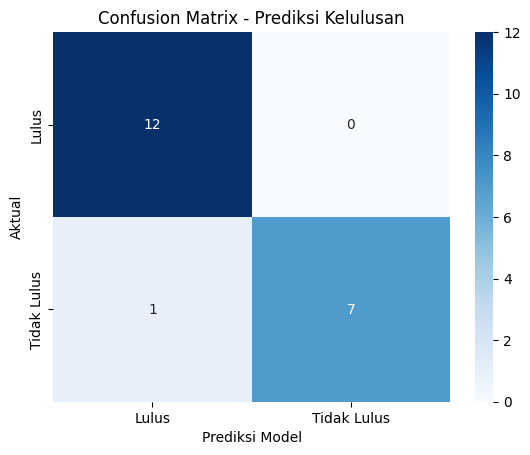

In [ ]:
# Menampilkan Confusion Matrix untuk mengecek kesalahan prediksi
cm = confusion_matrix(y_test, prediksi)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Lulus', 'Tidak Lulus'],
            yticklabels=['Lulus', 'Tidak Lulus'])
plt.title('Confusion Matrix - Prediksi Kelulusan')
plt.ylabel('Aktual')
plt.xlabel('Prediksi Model')
plt.show()